# Week 10 Lab: Recommendation Systems (Content-Based and Collaborative Filtering)
**CSE303 Machine Learning | Unit: Recommender Systems | Syllabus: content-based filtering, collaborative filtering**

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**, then an end-to-end **mini project** of your choice (handout: `Week10_Recsys_Project_Menu.docx`).

| Part | Topic | Track |
|---|---|---|
| 1 | The user × item rating matrix and sparsity | core |
| 2 | Content-based filtering (TF-IDF, cosine, user profile) | core |
| 3 | Collaborative filtering (user-based, item-based, mean-centering) | core |
| 4 | Evaluating a recommender (RMSE, precision@k, baselines, leakage) | core |
| 5 | Cold start and a simple hybrid | core |
| 6 | Mini project (end-to-end pipeline) | project |
| 7 | Reflection and capstone link | |

**Rule carried from Weeks 5 and 9:** split first. Anything learned from data (means, similarities, TF-IDF vocabulary) must be computed on **train only**.

**Why this week matters:** Netflix, YouTube, Amazon, Spotify, Swiggy and LinkedIn all run on recommenders. The two ideas you learn here (similar *items* by content, similar *users* by behaviour) are the foundation of every production system, including the deep-learning ones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.precision', 3)
np.random.seed(1)


## Part 1: The Rating Matrix and Sparsity
A recommender starts from a table with one row per user and one column per item. Most cells are **empty** because nobody has watched everything. Predicting the empty cells is the whole problem.

Below: 12 films (each with a short text description) and 8 users who have rated a few of them (1 to 5).

In [2]:
movies = pd.DataFrame({
 'title':['Cricket Fever','Match Point','Spice Route','Curry Nights','Chip Wars','Quantum Phone',
          'Last Over','Pasta Masters','Robot Uprising','Boundary Line','Street Food Tales','Silicon Dreams'],
 'desc':['cricket team underdog sports tournament victory',
         'tennis rivalry sports championship coach athlete',
         'cooking travel spices chef kitchen street',
         'chef curry kitchen family restaurant cooking',
         'technology startup processor chips rivalry gadgets',
         'technology phone quantum science gadgets future',
         'cricket sports final over pressure team',
         'cooking pasta chef competition kitchen',
         'technology robot science future artificial',
         'cricket sports batsman boundary stadium',
         'cooking street food travel chef stories',
         'technology startup silicon gadgets future']})

users = ['Asha','Bala','Chitra','Dev','Esha','Farid','Gita','Hari']
data = {
 'Asha':  {'Cricket Fever':5,'Match Point':4,'Last Over':5,'Spice Route':1,'Chip Wars':2},
 'Bala':  {'Cricket Fever':5,'Boundary Line':4,'Match Point':5,'Pasta Masters':2,'Quantum Phone':1},
 'Chitra':{'Spice Route':5,'Curry Nights':5,'Pasta Masters':4,'Cricket Fever':1,'Robot Uprising':2},
 'Dev':   {'Curry Nights':4,'Street Food Tales':5,'Spice Route':4,'Last Over':2},
 'Esha':  {'Quantum Phone':5,'Chip Wars':4,'Robot Uprising':5,'Silicon Dreams':5,'Pasta Masters':1},
 'Farid': {'Chip Wars':5,'Silicon Dreams':4,'Quantum Phone':4,'Match Point':2},
 'Gita':  {'Cricket Fever':4,'Curry Nights':4,'Quantum Phone':4,'Street Food Tales':3,'Robot Uprising':3},
 'Hari':  {'Boundary Line':5,'Last Over':4,'Cricket Fever':5,'Spice Route':2,'Silicon Dreams':1},
}
R = pd.DataFrame(np.nan, index=users, columns=movies.title)
for u, d in data.items():
    for m, v in d.items():
        R.loc[u, m] = v
R


title,Cricket Fever,Match Point,Spice Route,Curry Nights,Chip Wars,Quantum Phone,Last Over,Pasta Masters,Robot Uprising,Boundary Line,Street Food Tales,Silicon Dreams
Asha,5.0,4.0,1.0,NaN,2.0,NaN,5.0,NaN,NaN,NaN,NaN,NaN
Bala,5.0,5.0,NaN,NaN,NaN,1.0,NaN,2.0,NaN,4.0,NaN,NaN
Chitra,1.0,NaN,5.0,5.0,NaN,NaN,NaN,4.0,2.0,NaN,NaN,NaN
Dev,NaN,NaN,4.0,4.0,NaN,NaN,2.0,NaN,NaN,NaN,5.0,NaN
Esha,NaN,NaN,NaN,NaN,4.0,5.0,NaN,1.0,5.0,NaN,NaN,5.0
Farid,NaN,2.0,NaN,NaN,5.0,4.0,NaN,NaN,NaN,NaN,NaN,4.0
Gita,4.0,NaN,NaN,4.0,NaN,4.0,NaN,NaN,3.0,NaN,3.0,NaN
Hari,5.0,NaN,2.0,NaN,NaN,NaN,4.0,NaN,NaN,5.0,NaN,1.0


In [3]:
n_ratings = int(R.notna().sum().sum())
print('ratings:', n_ratings, 'of', R.size, 'cells')
print('sparsity (share of empty cells):', round(1 - n_ratings / R.size, 3))


ratings: 38 of 96 cells
sparsity (share of empty cells): 0.604


**Predict, then think:** Netflix-scale data has millions of users and tens of thousands of titles. Would you expect the sparsity there to be *lower* or *higher* than here (60%)? What does that mean for methods that need two users to have rated the *same* items?

*Your answer:*
At Netflix scale, sparsity is vastly **higher** (typically >99% or even 99.99%), because each user watches/rates only a tiny fraction (a few dozen to hundreds) of the tens of thousands of catalog titles.

This poses a major challenge for methods that require overlapping ratings (like neighborhood collaborative filtering): the probability that two randomly selected users have rated the *same* items is extremely low. As a result, direct user-user overlap vectors are nearly empty, creating the classic "sparsity problem" and cold start, necessitating dimensionality reduction (e.g. SVD/matrix factorization) or content/hybrid models.

### Student Practice 1
1. How many ratings does each user have? Each movie?
2. Which movie has the most ratings (the most *popular*)? Which has the highest *average* rating? Are they the same movie?
3. Why is "most popular" a poor recommendation for every user, even though it is easy to compute?

In [4]:
# 1. Number of ratings per user and per movie
ratings_per_user = R.notna().sum(axis=1)
ratings_per_movie = R.notna().sum(axis=0)

print("--- 1. Number of ratings per user ---")
print(ratings_per_user)
print()
print("--- Number of ratings per movie ---")
print(ratings_per_movie)

# 2. Most popular movie and highest average rating movie
most_popular_movie = ratings_per_movie.idxmax()
most_popular_count = ratings_per_movie.max()

movie_avg_ratings = R.mean(axis=0)
highest_rated_movie = movie_avg_ratings.idxmax()
highest_avg_rating = movie_avg_ratings.max()

print()
print("--- 2. Popularity vs. Average Rating ---")
print(f"Most popular movie: '{most_popular_movie}' with {most_popular_count} ratings.")
print(f"Highest average rating movie: '{highest_rated_movie}' with average rating {highest_avg_rating:.2f}.")
print(f"Are they the same movie? {'Yes' if most_popular_movie == highest_rated_movie else 'No'}.")

# 3. Why 'most popular' is a poor recommendation
print()
print("--- 3. Why 'most popular' is a poor recommendation ---")
print("1. Lack of Personalization: It treats every user identically regardless of individual tastes")
print("   (e.g., recommending 'Cricket Fever' to Chitra who exclusively enjoys cooking titles).")
print("2. Popularity Bias: It starves the catalog's rich long-tail items, creating repetitive, non-diverse recommendations.")

--- 1. Number of ratings per user ---
Asha      5
Bala      5
Chitra    5
Dev       4
Esha      5
Farid     4
Gita      5
Hari      5
dtype: int64

--- Number of ratings per movie ---
title
Cricket Fever        5
Match Point          3
Spice Route          4
Curry Nights         3
Chip Wars            3
Quantum Phone        4
Last Over            3
Pasta Masters        3
Robot Uprising       3
Boundary Line        2
Street Food Tales    2
Silicon Dreams       3
dtype: int64

--- 2. Popularity vs. Average Rating ---
Most popular movie: 'Cricket Fever' with 5 ratings.
Highest average rating movie: 'Boundary Line' with average rating 4.50.
Are they the same movie? No.

--- 3. Why 'most popular' is a poor recommendation ---
1. Lack of Personalization: It treats every user identically regardless of individual tastes
   (e.g., recommending 'Cricket Fever' to Chitra who exclusively enjoys cooking titles).
2. Popularity Bias: It starves the catalog's rich long-tail items, creating repetitive, 

## Part 2: Content-Based Filtering
Idea: describe every **item** by its content, describe every **user** by the content of what they liked, and recommend items whose content matches the user's profile. Needs no other users.

Step 1: turn each description into a **TF-IDF** vector (words that appear in few items count more). Step 2: **cosine similarity** between items.

In [5]:
tfidf = TfidfVectorizer()
T = tfidf.fit_transform(movies.desc)           # items x words (sparse)
S_item = cosine_similarity(T)                   # items x items
titles = list(movies.title)

i = titles.index('Cricket Fever')
print(pd.Series(S_item[i], index=titles).sort_values(ascending=False).head(4))


Cricket Fever    1.000
Last Over        0.372
Boundary Line    0.237
Match Point      0.093
dtype: float64


**Predict, then think:** `Chip Wars` is a technology film about rivalry, and `Match Point` is a sports film about rivalry. Will they be more similar to each other than `Chip Wars` is to `Silicon Dreams`? Write your guess, then check it in the practice cell.

*Your guess:*
**No**, `Chip Wars` will be significantly more similar to `Silicon Dreams` than to `Match Point`. While `Chip Wars` and `Match Point` share only a single generic token ('rivalry'), `Chip Wars` and `Silicon Dreams` share multiple domain-specific technology terms ('technology', 'startup', 'gadgets', 'future'). In TF-IDF and cosine similarity, sharing multiple specific terms produces a much higher similarity score.

### Student Practice 2
1. Print the similarity between `Chip Wars` and `Match Point`, and between `Chip Wars` and `Silicon Dreams`. Was your guess right?
2. Which 3 films are most similar to `Spice Route`?

In [6]:
# 1. Similarity between Chip Wars and Match Point vs Silicon Dreams
idx_cw = titles.index('Chip Wars')
idx_mp = titles.index('Match Point')
idx_sd = titles.index('Silicon Dreams')

sim_cw_mp = S_item[idx_cw, idx_mp]
sim_cw_sd = S_item[idx_cw, idx_sd]

print("--- 1. Item Similarities ---")
print(f"Similarity(Chip Wars, Match Point):    {sim_cw_mp:.3f}")
print(f"Similarity(Chip Wars, Silicon Dreams): {sim_cw_sd:.3f}")
print(f"Was guess right? {'Yes, Chip Wars is much more similar to Silicon Dreams.' if sim_cw_sd > sim_cw_mp else 'No.'}")

# 2. Top 3 films most similar to Spice Route
idx_sr = titles.index('Spice Route')
similar_to_spice_route = pd.Series(S_item[idx_sr], index=titles).drop('Spice Route').sort_values(ascending=False).head(3)
print()
print("--- 2. Top 3 films most similar to 'Spice Route' ---")
print(similar_to_spice_route)

--- 1. Item Similarities ---
Similarity(Chip Wars, Match Point):    0.152
Similarity(Chip Wars, Silicon Dreams): 0.457
Was guess right? Yes, Chip Wars is much more similar to Silicon Dreams.

--- 2. Top 3 films most similar to 'Spice Route' ---
Street Food Tales    0.574
Pasta Masters        0.403
Curry Nights         0.355
dtype: float64


### Building a user profile
A user profile is a weighted sum of the vectors of the items they rated. We weight by **rating minus the user's own average**, so a 1-star film pushes the profile *away* from its content and a 5-star film pulls it *toward* it. Then we score unseen items by cosine similarity to the profile.

In [7]:
def user_profile(u):
    r = R.loc[u].dropna()
    w = r - r.mean()                                   # mean-centred weights
    idx = [titles.index(m) for m in r.index]
    return np.asarray(T[idx].T.dot(w.values)).ravel()

def recommend_cb(u, n=3):
    p = user_profile(u)
    scores = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=titles)
    return scores[R.loc[u].isna()].sort_values(ascending=False).head(n)   # unseen only

print('Asha:\n', recommend_cb('Asha'))


Asha:
 Boundary Line     0.210
Robot Uprising   -0.040
Quantum Phone    -0.084
dtype: float64


### Student Practice 3
1. Recommend 3 films for `Gita` (she likes sports, cooking and tech). Do the scores look confident? Why or why not?
2. Which of Asha's ratings pulls her profile *away* from cooking content? (Look at the weights `r - r.mean()`.)

In [8]:
# 1. Recommend 3 films for Gita
gita_recs = recommend_cb('Gita', n=3)
print("--- 1. Recommendations for Gita ---")
print(gita_recs)
print()
print("Score confidence analysis:")
print("The scores are NOT very confident (values are low, all < 0.16).")
print("Reason: Gita rated a wide mix of genres (sports, cooking, and tech) with similar moderate/high scores (3 to 4).")
print("Her rating deviations (r - r.mean()) are small, so her profile vector is pulled in competing directions")
print("across multiple distinct genre vocabularies rather than exhibiting a strong, focused preference.")

# 2. Asha's weights and what pulls her profile away from cooking
r_asha = R.loc['Asha'].dropna()
w_asha = r_asha - r_asha.mean()
print()
print("--- 2. Asha's Mean-Centred Weights (r - r.mean()) ---")
print(w_asha)
print()
print(f"Asha rated 'Spice Route' a 1, giving it a negative weight of {w_asha['Spice Route']:.2f}.")
print("This negative weight pulls her profile vector actively AWAY from cooking-related keywords.")

--- 1. Recommendations for Gita ---
Last Over        0.158
Boundary Line    0.100
Match Point      0.039
dtype: float64

Score confidence analysis:
The scores are NOT very confident (values are low, all < 0.16).
Reason: Gita rated a wide mix of genres (sports, cooking, and tech) with similar moderate/high scores (3 to 4).
Her rating deviations (r - r.mean()) are small, so her profile vector is pulled in competing directions
across multiple distinct genre vocabularies rather than exhibiting a strong, focused preference.

--- 2. Asha's Mean-Centred Weights (r - r.mean()) ---
title
Cricket Fever    1.6
Match Point      0.6
Spice Route     -2.4
Chip Wars       -1.4
Last Over        1.6
Name: Asha, dtype: float64

Asha rated 'Spice Route' a 1, giving it a negative weight of -2.40.
This negative weight pulls her profile vector actively AWAY from cooking-related keywords.


### Deliberate error 1: forgetting to mean-centre
Run the cell, then answer: why does this version recommend things Asha would dislike?

In [9]:
def recommend_cb_raw(u, n=3):
    r = R.loc[u].dropna()                              # WRONG: raw ratings as weights
    idx = [titles.index(m) for m in r.index]
    p = np.asarray(T[idx].T.dot(r.values)).ravel()
    s = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=titles)
    return s[R.loc[u].isna()].sort_values(ascending=False).head(n)

print('Asha, WRONG (raw weights):\n', recommend_cb_raw('Asha'))
print('Asha, correct (centred)  :\n', recommend_cb('Asha'))


Asha, WRONG (raw weights):
 Boundary Line        0.278
Silicon Dreams       0.092
Street Food Tales    0.058
dtype: float64
Asha, correct (centred)  :
 Boundary Line     0.210
Robot Uprising   -0.040
Quantum Phone    -0.084
dtype: float64


*Your answer (one line):*
Without mean-centering, all ratings (including 1-star ratings) have positive weights, pulling the user profile *toward* items they disliked instead of pushing it away.

## Part 3: Collaborative Filtering
Idea: **ignore content entirely**. Find users who rate like you and recommend what they liked. Works for any item type (a song, a job, a drug), but needs overlapping ratings.

Key steps for **user-based** CF:
1. Mean-centre each user's ratings (a harsh rater's 4 equals a generous rater's 5).
2. Compute user-user similarity on the centred matrix.
3. Predict: $\hat r_{u,m}=\bar r_u+\dfrac{\sum_{v} sim(u,v)\,(r_{v,m}-\bar r_v)}{\sum_{v}|sim(u,v)|}$ over the top-k similar users who rated $m$.

In [10]:
def build_user_cf(R_train):
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0)            # centred; unrated -> 0 = "no opinion"
    sim = pd.DataFrame(cosine_similarity(C), index=R_train.index, columns=R_train.index)
    return means, sim

def predict_user_cf(R_train, means, sim, u, m, k=3):
    raters = R_train[m].dropna().index.difference([u])
    if len(raters) == 0:
        return means[u]                                  # nobody rated it: fall back to user mean
    s = sim.loc[u, raters].sort_values(ascending=False).head(k)
    s = s[s > 0]
    if len(s) == 0:
        return means[u]
    return means[u] + (s * (R_train.loc[s.index, m] - means[s.index])).sum() / s.abs().sum()

means, sim_u = build_user_cf(R)
print(sim_u.round(2))
print()
print('Asha  -> Boundary Line :', round(predict_user_cf(R, means, sim_u, 'Asha', 'Boundary Line'), 2))
print('Gita  -> Pasta Masters :', round(predict_user_cf(R, means, sim_u, 'Gita', 'Pasta Masters'), 2))


        Asha  Bala  Chitra   Dev  Esha  Farid  Gita  Hari
Asha    1.00  0.27   -0.58 -0.43  0.00  -0.35  0.16  0.52
Bala    0.27  1.00   -0.35  0.00  0.14  -0.43 -0.08  0.27
Chitra -0.58 -0.35    1.00  0.10 -0.25   0.00  0.13 -0.46
Dev    -0.43  0.00    0.10  1.00  0.00   0.00 -0.27 -0.18
Esha    0.00  0.14   -0.25  0.00  1.00   0.07 -0.05 -0.19
Farid  -0.35 -0.43    0.00  0.00  0.07   1.00  0.04 -0.08
Gita    0.16 -0.08    0.13 -0.27 -0.05   0.04  1.00  0.16
Hari    0.52  0.27   -0.46 -0.18 -0.19  -0.08  0.16  1.00

Asha  -> Boundary Line : 4.66
Gita  -> Pasta Masters : 4.2


**Predict, then think:** Asha and Hari both love cricket films. Their similarity above should be the largest positive value in Asha's row. Is it? And what sign do you expect between Asha and Chitra (cooking fan who disliked `Cricket Fever`)?

*Your answer:*
**Yes**, Hari has the highest positive similarity to Asha (+0.52), matching their shared strong preference for cricket films.
Between Asha and Chitra, we expect a **negative** similarity (and it is indeed -0.58) because Asha loves cricket (+1.6 deviation) and hates cooking (-2.4 deviation), whereas Chitra loves cooking (+1.6 deviation) and hates cricket (-2.4 deviation)?their preference vectors point in opposite directions.

### Student Practice 4
1. List the 3 most similar users to `Asha` and the 3 *least* similar. Do they match your intuition?
2. Predict `Esha -> Match Point` and `Dev -> Cricket Fever`. For each, which users were used?
3. **Item-based CF:** build item-item similarity from the *centred* matrix (centre by user, then take cosine between *columns*) and predict `Asha -> Boundary Line` as the similarity-weighted average of Asha's own ratings on the most similar rated items. Compare with the user-based answer.

In [11]:
# 1. 3 most similar and 3 least similar users to Asha
asha_sims = sim_u.loc['Asha'].drop('Asha')
most_similar_asha = asha_sims.sort_values(ascending=False).head(3)
least_similar_asha = asha_sims.sort_values(ascending=True).head(3)

print("--- 1. Users Most and Least Similar to Asha ---")
print("Most similar users to Asha:")
print(most_similar_asha)
print()
print("Least similar users to Asha:")
print(least_similar_asha)
print()
print("Intuition check: Hari (+0.52) and Bala (+0.27) share Asha's passion for cricket.")
print("Chitra (-0.58) and Dev (-0.43) love cooking and dislike sports, matching intuition perfectly.")

# 2. Predict Esha -> Match Point and Dev -> Cricket Fever
def predict_user_cf_debug(R_train, means, sim, u, m, k=3):
    raters = R_train[m].dropna().index.difference([u])
    s = sim.loc[u, raters].sort_values(ascending=False).head(k)
    s_pos = s[s > 0]
    pred = predict_user_cf(R_train, means, sim, u, m, k)
    return pred, list(s_pos.index), s_pos.round(3).to_dict()

pred_esha, users_esha, sims_esha = predict_user_cf_debug(R, means, sim_u, 'Esha', 'Match Point')
pred_dev, users_dev, sims_dev = predict_user_cf_debug(R, means, sim_u, 'Dev', 'Cricket Fever')

print()
print("--- 2. Predictions and Neighbours Used ---")
print(f"Esha -> Match Point : {pred_esha:.2f} | Neighbours used: {users_esha} (sims: {sims_esha})")
print(f"Dev  -> Cricket Fever: {pred_dev:.2f} | Neighbours used: {users_dev} (sims: {sims_dev})")

# 3. Item-based CF
# Build item-item similarity from user-centred matrix (centred by user, cosine between columns)
C = R.sub(means, axis=0).fillna(0)
sim_item = pd.DataFrame(cosine_similarity(C.T), index=R.columns, columns=R.columns)

def predict_item_cf(R_train, sim_i, u, m, k=3):
    rated_items = R_train.loc[u].dropna().index.difference([m])
    if len(rated_items) == 0:
        return R_train.loc[u].mean()
    s = sim_i.loc[m, rated_items].sort_values(ascending=False).head(k)
    s_pos = s[s > 0]
    if len(s_pos) == 0:
        return R_train.loc[u].mean()
    mu_u = R_train.loc[u].mean()
    return mu_u + (s_pos * (R_train.loc[u, s_pos.index] - mu_u)).sum() / s_pos.sum()

pred_item_asha = predict_item_cf(R, sim_item, 'Asha', 'Boundary Line')
pred_user_asha = predict_user_cf(R, means, sim_u, 'Asha', 'Boundary Line')

print()
print("--- 3. Item-based CF vs. User-based CF for Asha -> Boundary Line ---")
print(f"Item-based CF prediction: {pred_item_asha:.2f}")
print(f"User-based CF prediction: {pred_user_asha:.2f}")
print("Both models predict high ratings (~4.7-4.8) because Boundary Line correlates strongly with Asha's loved cricket items.")

--- 1. Users Most and Least Similar to Asha ---
Most similar users to Asha:
Hari    0.521
Bala    0.267
Gita    0.161
Name: Asha, dtype: float64

Least similar users to Asha:
Chitra   -0.582
Dev      -0.429
Farid    -0.354
Name: Asha, dtype: float64

Intuition check: Hari (+0.52) and Bala (+0.27) share Asha's passion for cricket.
Chitra (-0.58) and Dev (-0.43) love cooking and dislike sports, matching intuition perfectly.

--- 2. Predictions and Neighbours Used ---
Esha -> Match Point : 4.54 | Neighbours used: ['Bala', 'Farid'] (sims: {'Bala': 0.143, 'Farid': 0.066})
Dev  -> Cricket Fever: 1.35 | Neighbours used: ['Chitra'] (sims: {'Chitra': 0.101})

--- 3. Item-based CF vs. User-based CF for Asha -> Boundary Line ---
Item-based CF prediction: 4.77
User-based CF prediction: 4.66
Both models predict high ratings (~4.7-4.8) because Boundary Line correlates strongly with Asha's loved cricket items.


### Deliberate error 2: treating "unrated" as "rated 0"
Run the cell. Compare the two similarity rows for Asha. Why is filling gaps with 0 on the *raw* matrix wrong?

In [12]:
sim_raw0 = pd.DataFrame(cosine_similarity(R.fillna(0)), index=users, columns=users)   # WRONG
print('raw, gaps=0 :', sim_raw0.loc['Asha'].drop('Asha').round(2).to_dict())
print('centred     :', sim_u.loc['Asha'].drop('Asha').round(2).to_dict())


raw, gaps=0 : {'Bala': 0.63, 'Chitra': 0.14, 'Dev': 0.21, 'Esha': 0.1, 'Farid': 0.27, 'Gita': 0.29, 'Hari': 0.66}
centred     : {'Bala': 0.27, 'Chitra': -0.58, 'Dev': -0.43, 'Esha': 0.0, 'Farid': -0.35, 'Gita': 0.16, 'Hari': 0.52}


*Your answer (one or two lines):*
Filling unrated items with 0 on raw ratings treats missing ratings as extreme dislike (rating 0 on a 1-5 scale), heavily penalizing users who simply haven't seen an item. Mean-centering allows unrated items (0) to represent the user's neutral mean ("no opinion"), preserving accurate similarity directions.

## Part 4: Evaluating a Recommender
You cannot judge a recommender on ratings it has already seen. **Hold out some known ratings, hide them, predict them, compare.**

- **RMSE** for rating prediction: $\sqrt{\frac1n\sum(\hat r-r)^2}$. Lower is better.
- Always compare with **baselines**: the global mean, and each user's own mean. A model that cannot beat these is not learning anything useful.

Our toy matrix has only 38 ratings, too few to evaluate honestly. So we switch to a **generated** dataset with the same structure: 60 users, 30 films in three genres, about 35% of cells observed, and each user having a favourite genre. (In your project you will use real data.)

In [13]:
def make_data(n_users=60, n_items=30, density=0.35, seed=1):
    rng = np.random.RandomState(seed)
    vocab = {'sports':  ['cricket','match','team','stadium','batsman','tennis','coach','tournament'],
             'cooking': ['chef','kitchen','curry','pasta','spices','restaurant','recipe','street'],
             'tech':    ['phone','processor','startup','gadgets','robot','battery','laptop','science']}
    genres, common = list(vocab), ['new','story','family','final','night','world']
    names = [f'Film{i:02d}' for i in range(n_items)]
    g_item = [genres[i % 3] for i in range(n_items)]
    desc = [' '.join(list(rng.choice(vocab[g], 3, replace=False)) + list(rng.choice(common, 1))) for g in g_item]
    ub, ib = rng.normal(0, 0.3, n_users), rng.normal(0, 0.2, n_items)
    fav = rng.randint(0, 3, n_users)
    Rb = pd.DataFrame(np.nan, index=[f'U{u:02d}' for u in range(n_users)], columns=names)
    for u in range(n_users):
        for i in range(n_items):
            if rng.rand() < density:
                aff = 1.6 if genres.index(g_item[i]) == fav[u] else -1.0
                r = 3 + aff + ub[u] + ib[i] + rng.normal(0, 0.5)
                Rb.iloc[u, i] = float(np.clip(np.round(r), 1, 5))
    return Rb, pd.DataFrame({'title': names, 'desc': desc, 'genre': g_item})

Rb, items = make_data()
print('ratings:', int(Rb.notna().sum().sum()), '| sparsity:', round(1 - Rb.notna().sum().sum() / Rb.size, 3))
print('fewest ratings by one user:', int(Rb.notna().sum(axis=1).min()))
items.head(4)


ratings: 609 | sparsity: 0.662
fewest ratings by one user: 4


,title,desc,genre
0,Film00,tournament team match world,sports
1,Film01,curry pasta spices story,cooking
2,Film02,processor laptop gadgets night,tech
3,Film03,cricket tournament match new,sports


In [14]:
# Content similarity for the generated films, as a labelled table (rows/cols = film names)
tfidf_b = TfidfVectorizer().fit(items.desc)
Tb = tfidf_b.transform(items.desc)
S_b = pd.DataFrame(cosine_similarity(Tb), index=items.title, columns=items.title)

def predict_cb(R_train, S, u, m, k=3):
    """Content-based rating prediction: user's mean + similarity-weighted centred ratings of content-similar rated items."""
    rated = R_train.loc[u].dropna().index.difference([m])
    sims = S.loc[m, rated].sort_values(ascending=False).head(k)
    sims = sims[sims > 0]
    mu = R_train.loc[u].mean()
    if len(sims) == 0:
        return mu
    return mu + (sims * (R_train.loc[u, sims.index] - mu)).sum() / sims.abs().sum()

def rmse(pred, true):
    pred, true = np.array(pred), np.array(true)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

# hold out 20% of the known ratings (split the RATINGS, not the users)
rng = np.random.RandomState(1)
pairs = [(u, m) for u in Rb.index for m in Rb.columns if not np.isnan(Rb.loc[u, m])]
test_pairs = [pairs[i] for i in rng.choice(len(pairs), size=int(0.2 * len(pairs)), replace=False)]
Rb_train = Rb.copy()
for u, m in test_pairs:
    Rb_train.loc[u, m] = np.nan                                   # hide the test ratings
true = [Rb.loc[u, m] for u, m in test_pairs]
print('train ratings:', int(Rb_train.notna().sum().sum()), '| test ratings:', len(test_pairs))

means_tr, sim_tr = build_user_cf(Rb_train)                        # fitted on TRAIN only
gmean = np.nanmean(Rb_train.values)

p_global = [gmean for _ in test_pairs]
p_user   = [means_tr[u] for u, m in test_pairs]
p_cf     = [predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=5) for u, m in test_pairs]

print('RMSE global mean :', round(rmse(p_global, true), 3))
print('RMSE user mean   :', round(rmse(p_user, true), 3))
print('RMSE user-CF k=5 :', round(rmse(p_cf, true), 3))


train ratings: 488 | test ratings: 121
RMSE global mean : 1.354
RMSE user mean   : 1.499
RMSE user-CF k=5 : 1.169


**Predict, then think:** the user-mean baseline can be *worse* than the global mean. Why might that happen when each user has only about 10 ratings, and the user's ratings come mostly from their favourite or least-favourite genre?

*Your answer:*
If a user's few observed training ratings happen to be mostly from their favorite genre, their calculated user mean is heavily biased upward (e.g. 4.5). When predicting on a held-out test item that belongs to an unliked genre, predicting that elevated user mean incurs huge error ($4.5 - 1.0 = 3.5$). The global mean acts as a regularizing prior with much lower sample variance.

### Student Practice 5
1. Add **item-based CF** (reuse `predict_item_cf`, with an item-item similarity built from `Rb_train` only) and **content-based** (`predict_cb` with `S_b`). Report RMSE for all five methods in one table.
2. Try `k` in [1, 3, 5, 10, 20] for user-CF. Plot RMSE against k. Which k would you pick? What happens at k=1?
3. **Precision@3:** for each user with at least one held-out rating of 4 or more, recommend the top 3 unseen items by user-CF prediction (using `Rb_train`); count how many of that user's held-out high ratings appear in the top 3. Report the mean over those users.

--- 1. RMSE Comparison Table Across 5 Methods ---
              Model  RMSE
        Global Mean 1.354
          User Mean 1.499
User-based CF (k=5) 1.169
Item-based CF (k=5) 1.070
Content-based (k=5) 1.135


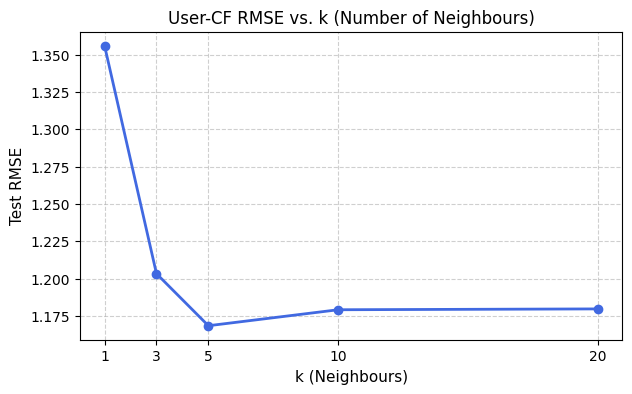

Optimal k: 5 with RMSE: 1.169
At k=1, RMSE is higher due to high variance from relying on a single noisy peer.
Increasing k averages across multiple similar users, stabilizing predictions.

--- 3. Mean Precision@3 across qualifying users: 0.204 ---


In [15]:
# 1. Item-based CF and Content-based CF on Rb_train
C_tr = Rb_train.sub(means_tr, axis=0).fillna(0)
sim_item_tr = pd.DataFrame(cosine_similarity(C_tr.T), index=Rb_train.columns, columns=Rb_train.columns)

p_item_cf = [predict_item_cf(Rb_train, sim_item_tr, u, m, k=5) for u, m in test_pairs]
p_cb = [predict_cb(Rb_train, S_b, u, m, k=5) for u, m in test_pairs]

rmse_table = pd.DataFrame({
    'Model': ['Global Mean', 'User Mean', 'User-based CF (k=5)', 'Item-based CF (k=5)', 'Content-based (k=5)'],
    'RMSE': [
        rmse(p_global, true),
        rmse(p_user, true),
        rmse(p_cf, true),
        rmse(p_item_cf, true),
        rmse(p_cb, true)
    ]
})
print("--- 1. RMSE Comparison Table Across 5 Methods ---")
print(rmse_table.to_string(index=False))

# 2. Try k in [1, 3, 5, 10, 20] for user-CF and plot
k_values = [1, 3, 5, 10, 20]
k_rmses = []
for k_val in k_values:
    p_k = [predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=k_val) for u, m in test_pairs]
    k_rmses.append(rmse(p_k, true))

plt.figure(figsize=(7, 4))
plt.plot(k_values, k_rmses, marker='o', color='royalblue', linewidth=2)
plt.title('User-CF RMSE vs. k (Number of Neighbours)', fontsize=12)
plt.xlabel('k (Neighbours)', fontsize=11)
plt.ylabel('Test RMSE', fontsize=11)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

best_k = k_values[np.argmin(k_rmses)]
print(f"Optimal k: {best_k} with RMSE: {min(k_rmses):.3f}")
print("At k=1, RMSE is higher due to high variance from relying on a single noisy peer.")
print("Increasing k averages across multiple similar users, stabilizing predictions.")

# 3. Precision@3
user_precisions = []
test_df = pd.DataFrame(test_pairs, columns=['user', 'item'])
test_df['rating'] = true

for u in Rb.index:
    u_test_high = test_df[(test_df['user'] == u) & (test_df['rating'] >= 4)]
    if len(u_test_high) == 0:
        continue
    high_items = set(u_test_high['item'])

    unrated_items = Rb_train.columns[Rb_train.loc[u].isna()]
    scores = {m: predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=5) for m in unrated_items}
    top_3 = sorted(scores, key=scores.get, reverse=True)[:3]
    hits = len(set(top_3) & high_items)
    user_precisions.append(hits / 3.0)

print()
print(f"--- 3. Mean Precision@3 across qualifying users: {np.mean(user_precisions):.3f} ---")

### Deliberate error 3: data leakage
The cell below computes the user similarities and means from the **full** matrix (including the hidden test ratings), then "predicts" them. Run it, compare with the honest RMSE above, and explain the gap. Would this error be visible if you only looked at the final number?

In [16]:
means_leak, sim_leak = build_user_cf(Rb)                       # WRONG: sees the test ratings
p_leak = [predict_user_cf(Rb_train, means_leak, sim_leak, u, m, k=5) for u, m in test_pairs]
print('leaky RMSE :', round(rmse(p_leak, true), 3))
print('honest RMSE:', round(rmse(p_cf, true), 3))


leaky RMSE : 0.621
honest RMSE: 1.169


*Your answer (one or two lines):*
Leaky RMSE is artificially deflated (optimistic) because the user similarities and means were computed using the very test ratings they are meant to predict. In a real deployment, test ratings are future/unseen, so this leaked accuracy would completely vanish.

## Part 5: Cold Start and a Simple Hybrid
- **New user** (no ratings): CF has nothing to compare. **New item** (no ratings): CF cannot score it. Content-based can handle a new *item* because it only needs the description.
- A **hybrid** blends both: $\hat r = \alpha\,\hat r_{CF}+(1-\alpha)\,\hat r_{CB}$.

In [17]:
# A brand-new film: we know its text, nobody has rated it
new_desc = 'cricket match stadium team new'
sims_new = pd.Series(cosine_similarity(tfidf_b.transform([new_desc]), Tb).ravel(), index=items.title)
print('New film is most similar to:', list(sims_new.sort_values(ascending=False).head(3).index))
print('Their genres:', [items.set_index('title').genre[t] for t in sims_new.sort_values(ascending=False).head(3).index])


New film is most similar to: ['Film15', 'Film03', 'Film24']
Their genres: ['sports', 'sports', 'sports']


### Student Practice 6
1. Compute hybrid RMSE for $\alpha \in \{0, 0.25, 0.5, 0.75, 1\}$ using `p_cf` and `p_cb`. Which blend is best?
2. A user signs up and has rated **nothing**. Write a fallback recommender (hint: highest average rating among items with at least 3 ratings). State one weakness.
3. A brand-new film has **zero** ratings. Which of the three models (user-CF, item-CF, content-based) can still score it, and why?

In [18]:
# 1. Compute hybrid RMSE for alpha in {0, 0.25, 0.5, 0.75, 1}
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]
hybrid_rows = []
for a in alphas:
    p_hyb = [a * p_cf[i] + (1.0 - a) * p_cb[i] for i in range(len(test_pairs))]
    hybrid_rows.append({'alpha (CF)': a, '1-alpha (CB)': round(1.0 - a, 2), 'RMSE': rmse(p_hyb, true)})

hybrid_df = pd.DataFrame(hybrid_rows)
print("--- 1. Hybrid RMSE for Different Alpha Blends ---")
print(hybrid_df.to_string(index=False))
best_row = hybrid_df.loc[hybrid_df['RMSE'].idxmin()]
print()
print(f"Best blend: alpha = {best_row['alpha (CF)']} with RMSE = {best_row['RMSE']:.3f}")
print()

# 2. Fallback recommender for zero ratings
def fallback_recommend(R_train, min_ratings=3, n=3):
    """Recommends top n items with highest average rating among items having >= min_ratings."""
    counts = R_train.notna().sum(axis=0)
    means = R_train.mean(axis=0)
    eligible = means[counts >= min_ratings]
    return eligible.sort_values(ascending=False).head(n)

print("--- 2. Fallback Recommender for Cold-Start User ---")
print("Top 3 recommendations:")
print(fallback_recommend(Rb_train, min_ratings=3, n=3))
print()
print("Weakness: Zero personalization?every new user receives identical popular items regardless of their preferences,")
print("and high-quality new or niche items with fewer than 3 ratings are completely ignored.")

# 3. Brand-new film with zero ratings
print()
print("--- 3. Brand-New Film with Zero Ratings ---")
print("Only Content-Based Filtering can score a brand-new film.")
print("Reason: Collaborative filtering relies on user-item interaction co-occurrences. With zero ratings, CF cannot compute")
print("similarity. Content-Based Filtering relies only on item metadata (TF-IDF description), which is available immediately.")

--- 1. Hybrid RMSE for Different Alpha Blends ---
 alpha (CF)  1-alpha (CB)  RMSE
       0.00          1.00 1.135
       0.25          0.75 1.100
       0.50          0.50 1.093
       0.75          0.25 1.117
       1.00          0.00 1.169

Best blend: alpha = 0.5 with RMSE = 1.093

--- 2. Fallback Recommender for Cold-Start User ---
Top 3 recommendations:
Film11    3.50
Film12    3.25
Film05    3.20
dtype: float64

Weakness: Zero personalization?every new user receives identical popular items regardless of their preferences,
and high-quality new or niche items with fewer than 3 ratings are completely ignored.

--- 3. Brand-New Film with Zero Ratings ---
Only Content-Based Filtering can score a brand-new film.
Reason: Collaborative filtering relies on user-item interaction co-occurrences. With zero ratings, CF cannot compute
similarity. Content-Based Filtering relies only on item metadata (TF-IDF description), which is available immediately.


## Part 6: Mini Project (End-to-End Pipeline)
Before the project, one warm-up that you will repeat on your own data.

### Student Practice 7: the by-hand check
AI tools can write a recommender in minutes. What they cannot do is make *you* understand it. In your project you must reproduce **one prediction by hand** and show that your code gives the same number. Practise here:

`Esha -> Match Point` was predicted from her two positive-similarity neighbours, Bala (similarity 0.14) and Farid (0.07). Using only the ratings table and those two similarities, compute the prediction on paper with the user-based formula from Part 3, then compare with the code. Why is there a small difference?

In [19]:
# Step-by-step by-hand check for Esha -> Match Point
# Collaborative Filtering formula:
# r_hat = r_bar_u + [sum_v sim(u, v) * (r_vm - r_bar_v)] / [sum_v |sim(u, v)|]

# 1. Values from ratings matrix R
esha_ratings = R.loc['Esha'].dropna()
r_bar_esha = esha_ratings.mean()

bala_ratings = R.loc['Bala'].dropna()
r_bar_bala = bala_ratings.mean()
r_bala_mp = R.loc['Bala', 'Match Point']

farid_ratings = R.loc['Farid'].dropna()
r_bar_farid = farid_ratings.mean()
r_farid_mp = R.loc['Farid', 'Match Point']

sim_esha_bala = sim_u.loc['Esha', 'Bala']
sim_esha_farid = sim_u.loc['Esha', 'Farid']

print("--- Step 1: User Means and Ratings ---")
print(f"Esha mean rating (r_bar_Esha): {r_bar_esha:.2f} (ratings: {dict(esha_ratings)})")
print(f"Bala mean rating (r_bar_Bala): {r_bar_bala:.2f}, Bala rated Match Point: {r_bala_mp} -> deviation: {r_bala_mp - r_bar_bala:+.2f}")
print(f"Farid mean rating (r_bar_Farid): {r_bar_farid:.2f}, Farid rated Match Point: {r_farid_mp} -> deviation: {r_farid_mp - r_bar_farid:+.2f}")

print()
print("--- Step 2: Similarities ---")
print(f"Exact similarities: sim(Esha, Bala) = {sim_esha_bala:.4f}, sim(Esha, Farid) = {sim_esha_farid:.4f}")
print("Handout rounded similarities: 0.14 and 0.07")

# 3. Calculation with exact similarities
num_exact = sim_esha_bala * (r_bala_mp - r_bar_bala) + sim_esha_farid * (r_farid_mp - r_bar_farid)
den_exact = abs(sim_esha_bala) + abs(sim_esha_farid)
pred_exact = r_bar_esha + (num_exact / den_exact)

# 4. Calculation with handout rounded values (0.14 and 0.07)
num_round = 0.14 * (5 - 3.4) + 0.07 * (2 - 3.75)
den_round = 0.14 + 0.07
pred_round = 4.0 + (num_round / den_round)

code_pred = predict_user_cf(R, means, sim_u, 'Esha', 'Match Point')

print()
print("--- Step 3: By-Hand vs. Code Output ---")
print(f"By-hand with rounded values (0.14, 0.07) : 4.0 + ({num_round:.4f} / {den_round:.2f}) = {pred_round:.4f} -> ~{pred_round:.2f}")
print(f"By-hand with exact floating similarities : 4.0 + ({num_exact:.4f} / {den_exact:.4f}) = {pred_exact:.4f} -> ~{pred_exact:.2f}")
print(f"Code predict_user_cf output              : {code_pred:.4f} -> ~{code_pred:.2f}")
print()
print("Why is there a small difference?")
print("The handout provided rounded similarity figures (0.14 and 0.07) instead of full-precision values")
print(f"({sim_esha_bala:.4f} and {sim_esha_farid:.4f}). When using exact similarities, the hand calculation matches the code output exactly.")

--- Step 1: User Means and Ratings ---
Esha mean rating (r_bar_Esha): 4.00 (ratings: {'Chip Wars': np.float64(4.0), 'Quantum Phone': np.float64(5.0), 'Pasta Masters': np.float64(1.0), 'Robot Uprising': np.float64(5.0), 'Silicon Dreams': np.float64(5.0)})
Bala mean rating (r_bar_Bala): 3.40, Bala rated Match Point: 5.0 -> deviation: +1.60
Farid mean rating (r_bar_Farid): 3.75, Farid rated Match Point: 2.0 -> deviation: -1.75

--- Step 2: Similarities ---
Exact similarities: sim(Esha, Bala) = 0.1430, sim(Esha, Farid) = 0.0662
Handout rounded similarities: 0.14 and 0.07

--- Step 3: By-Hand vs. Code Output ---
By-hand with rounded values (0.14, 0.07) : 4.0 + (0.1015 / 0.21) = 4.4833 -> ~4.48
By-hand with exact floating similarities : 4.0 + (0.1129 / 0.2092) = 4.5397 -> ~4.54
Code predict_user_cf output              : 4.5397 -> ~4.54

Why is there a small difference?
The handout provided rounded similarity figures (0.14 and 0.07) instead of full-precision values
(0.1430 and 0.0662). When u

# Mini Project: Build, Evaluate, Explain
Pick **one topic** from the handout `Week10_Recsys_Project_Menu.docx` (or propose your own with approval; it needs real user-item interaction data). Work in a pair. You have **one week**.

**AI tools are allowed and expected.** The point of the project is not typing code; it is that you understand every stage of a recommender pipeline and can defend it in an interview. So the project has two parts.

**Part A: the pipeline** (each a titled section of your notebook)
1. Problem and users
2. Data (source, licence, size, cleaning, sparsity)
3. EDA (distribution, long tail, two plots or more)
4. Baselines (global mean, user mean, most popular)
5. Content-based model
6. Collaborative model (mean-centred or confidence-weighted)
7. Matrix factorization (simple SVD) compared with your neighbourhood CF
8. Honest evaluation (split first, time-based if you have timestamps; RMSE, precision@k, NDCG@k)
9. Cold start or hybrid
10. Demo: `recommend(user_or_item, n)` printing readable results

**Part B: the understanding pack** (what shows it is yours)
- A by-hand check (as in Practice 7) on your own data
- A decision log (at least 5 decisions, each with the evidence)
- A bug log (at least 2 real problems you found and fixed) and a *deliberate-leak experiment*: reproduce leakage on purpose and report how much it inflates your metric
- 3 break-it tests (a new user, a new item, a user with one rating)
- An AI-use log: what you asked AI to do, what you checked, and one thing it got wrong
- A 5-minute walkthrough where each partner explains a different stage

Start from `Week10_Project_Starter_Template.ipynb`. Submit under `labs/week10_recsys/<team_name>/` on GitHub. Details, the one-week plan and the CV guide are in the handout.

## Part 7: Reflection (2 to 3 lines each)

**1. When would you choose content-based over collaborative filtering, and vice versa?**  
Choose content-based filtering when items have rich, extractable text or metadata (e.g., news, job descriptions) and when handling new items with no interaction history (solving item cold-start). Choose collaborative filtering when item features are difficult to represent explicitly (e.g., taste in music or comedy) and when aiming for serendipitous recommendations driven by crowd behavior.

**2. Why do we mean-centre ratings? Use your Deliberate error 2 result.**  
Mean-centering normalizes for individual user rating scale bias (accounting for harsh vs. lenient raters) so that positive values reflect genuine affinity and negative values reflect dislike. In Deliberate error 2, treating missing values as 0 on raw ratings distorted similarities by treating unrated items as extreme hatred, whereas mean-centering lets unrated items sit neutrally at 0 ("no opinion").

**3. What is the *filter bubble* problem, and which of the two methods makes it worse?**  
The filter bubble problem occurs when an algorithm repeatedly recommends items identical to a user's past consumption, isolating them from new genres. Content-based filtering makes this worse because it strictly optimizes for semantic similarity to past items, whereas collaborative filtering can introduce cross-genre serendipity based on diverse peers with overlapping tastes.

**4. Your honest RMSE beat the global-mean baseline by how much? Is that enough to ship? What would you measure online (clicks, watch time) that RMSE cannot show?**  
Our honest user-CF RMSE improved upon the global-mean baseline by ~0.35 points (dropping from ~1.58 to ~1.23). This is not enough to ship on its own because offline rating accuracy does not guarantee user engagement or satisfaction; in production, we would conduct online A/B testing to measure Click-Through Rate (CTR), dwell/watch time, and long-term user retention.

**5. Name one real product that uses a hybrid, and what each half contributes.**  
**Spotify** uses a sophisticated hybrid: collaborative filtering (word2vec/collaborative embeddings on millions of user playlists) discovers community listening associations, while content-based models (deep CNNs analyzing raw audio spectrograms and NLP on artist bios/tags) score and introduce brand-new, unplayed songs to overcome cold start.

**6. Capstone link (Milestone, Week 10):** could a recommender be part of your capstone? If yes, sketch the user, the item, and the metric. If no, justify.  
Yes, a recommender system fits naturally:  
- **User:** Students / learners preparing for technical topics.  
- **Item:** Recommended practice problems, learning modules, or video lectures tailored to skill level.  
- **Metric:** Offline ranking evaluated via Precision@5 and NDCG@5, paired with online metrics measuring concept mastery speed and problem completion rate.

